In [1]:
import pandas as pd
import numpy as np

In [2]:
data=pd.read_csv(r"C:\Users\VP\Downloads\bank.csv")

In [5]:
data=data.replace('unknown',np.nan)
from sklearn.model_selection import train_test_split
x=data.drop(columns='deposit')
y=data['deposit']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

number=x_train.describe(include='number').columns.to_list()
catagory=x_train.describe(exclude='number').columns.to_list()


In [ ]:
from sklearn.preprocessing import(OneHotEncoder,StandardScaler,PowerTransformer,MinMaxScaler,FunctionTransformer)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

age_number_pipe=Pipeline([('imputer',SimpleImputer(strategy='mean')),
                          ('transform',FunctionTransformer(np.log1p)),
                          ('scalar',MinMaxScaler())])
balance_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())])

day_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scalar',MinMaxScaler())])

duration_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',FunctionTransformer(np.log1p)),
    ('scalar',StandardScaler())])

campaign_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),
                          ('transorm',FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
                          ('scalar',StandardScaler())])

pdays_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())])

prevoius_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())])


job_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=int,drop='first')),
    ])

preprocessor = ColumnTransformer([
    ('balance_pipe',balance_pipe,['balance']),
    ('age_number_pipe',age_number_pipe,['age']),
    ('day_pipe',day_pipe,['day']),
    ('duration_pipe',duration_pipe,['duration']),
    ('campaign_pipe',campaign_pipe,['campaign']),
    ('pdays_pipe',pdays_pipe,['pdays']),
    ('prevoius_pipe',prevoius_pipe,['previous']),
    ('job_pipe',job_pipe,['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome']),],remainder='passthrough')
preprocessor.set_output(transform="pandas")


x_train_final=preprocessor.fit_transform(x_train)
x_test_final=preprocessor.transform(x_test)


In [126]:
# import matplotlib.pyplot as plt

# x_train['day'].hist(bins=31, figsize=(16,12))

x_train_final

,tmp_col_name_0_0,tmp_col_name_1_0,tmp_col_name_2_0,tmp_col_name_3_0,tmp_col_name_4_0,tmp_col_name_5_0,tmp_col_name_6_0,tmp_col_name_7_0,tmp_col_name_7_1,tmp_col_name_7_2,...,tmp_col_name_7_23,tmp_col_name_7_24,tmp_col_name_7_25,tmp_col_name_7_26,tmp_col_name_7_27,tmp_col_name_7_28,tmp_col_name_7_29,tmp_col_name_7_30,tmp_col_name_7_31,tmp_col_name_7_32
3955,1.440574,0.261037,0.300000,1.688883,1.421915,1.748611,1.830018,0,0,0,...,0,0,0,0,0,0,1,0,0,0
11150,-0.307910,0.377126,0.666667,0.167986,0.579111,-0.578448,-0.577272,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5173,-0.381555,0.584836,0.300000,0.954526,-0.861671,1.683610,1.500969,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3017,0.299080,0.644817,0.466667,0.300758,-0.861671,-0.578448,-0.577272,0,1,0,...,0,0,0,0,0,0,0,1,0,0
2910,0.183543,0.644817,0.333333,-0.540962,0.579111,1.689646,1.882117,0,0,0,...,0,0,0,0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,-0.135935,0.572107,0.333333,-1.214966,-0.018868,-0.578448,-0.577272,0,0,0,...,1,0,0,0,0,0,0,1,0,0
5191,-0.403195,0.261037,0.500000,0.601742,-0.018868,1.565486,1.857719,0,0,0,...,0,0,0,0,1,0,0,0,0,1
5390,0.011123,0.394516,0.633333,-0.360050,3.183116,-0.578448,-0.577272,0,0,0,...,0,0,0,0,0,0,0,1,0,0
860,-0.141931,0.621519,0.800000,0.370893,1.421915,-0.578448,-0.577272,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [51]:
x_train["duration"]=x_train["duration"]/60

<Axes: >

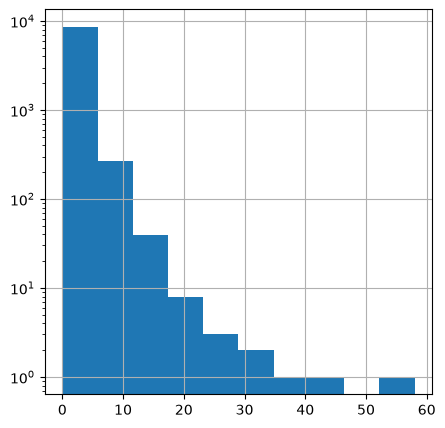

In [72]:
x_train['previous'].hist(bins=10, log=True,figsize=(5,5))

In [88]:
x_train['poutcome'].describe()

count        2240
unique          3
top       failure
freq          974
Name: poutcome, dtype: object

In [91]:
x_train['poutcome'].isna().mean()*100

np.float64(74.91320416620002)

In [86]:
x_train['contact']=x_train['contact'].fillna('no contact')

In [95]:
x_train['poutcome']=x_train['poutcome'].fillna('inprocess')

poutcome
inproces    6689
failure      974
success      849
other        417
Name: count, dtype: int64

In [127]:
print(type(x_train_final))
print(x_train_final.columns.tolist()[:8])
print(preprocessor.get_feature_names_out()[:8])

<class 'pandas.DataFrame'>
['tmp_col_name_0_0', 'tmp_col_name_1_0', 'tmp_col_name_2_0', 'tmp_col_name_3_0', 'tmp_col_name_4_0', 'tmp_col_name_5_0', 'tmp_col_name_6_0', 'tmp_col_name_7_0']


AttributeError: Estimator transform does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?